<a href="https://colab.research.google.com/github/DrDourado/ME_640_Optimum_Design_Fall_2026/blob/main/ME640_06_Data_Informed_AI_Connected_Design.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ME 640 – Optimum Design Methods
# Data-Informed and AI-Connected Design

## From data to prediction, from prediction to design decisions

Engineering design has traditionally relied on physics-based models, experiments, optimization algorithms, and engineering judgment. Modern design increasingly adds a second source of knowledge: **data**. Historical tests, simulation archives, sensor streams, manufacturing records, field observations, and digital twins can all inform future design decisions.

This notebook introduces two related ideas:

### Data-informed design
Design decisions are supported by patterns, models, uncertainty estimates, and evidence extracted from data.

### AI-connected design
AI/ML models are not treated as isolated predictors. They are connected to the design loop so that predictions, uncertainty, explanations, constraints, and new observations influence what design is selected or evaluated next.

A useful progression is

$
\boxed{\text{Data}\rightarrow\text{Information}\rightarrow\text{Predictive model}\rightarrow\text{Decision}\rightarrow\text{Design}\rightarrow\text{New data}}
$

### Learning objectives
By the end of the lecture, students should be able to:
1. distinguish data-driven, data-informed, and AI-connected design;
2. identify appropriate data sources for engineering design;
3. formulate supervised-learning problems from design data;
4. build and validate regression models without data leakage;
5. distinguish prediction accuracy from design usefulness;
6. use feature importance and partial dependence for engineering interpretation;
7. recognize interpolation, extrapolation, uncertainty, bias, and domain-of-validity issues;
8. connect an ML predictor to an optimization/search procedure;
9. describe closed-loop and human-in-the-loop AI-connected design.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, cross_validate
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from scipy.stats import qmc

RANDOM_STATE=640
np.random.seed(RANDOM_STATE)

# 1. What does “data-informed design” mean?

A conventional design problem is often written

$$
\min_{\mathbf{x}} f(\mathbf{x})
$$

subject to

$$
g_j(\mathbf{x})\le 0,\qquad \mathbf{x}^L\le\mathbf{x}\le\mathbf{x}^U.
$$

The traditional assumption is that the designer has explicit equations or simulations for $f$ and $g_j$. In many modern systems, however, useful knowledge also exists in data.

**Data-informed design** uses that evidence to improve one or more parts of the design process. Data can help us:
- estimate an unavailable response;
- calibrate uncertain model parameters;
- identify influential variables;
- discover interactions or nonlinearities;
- estimate manufacturing or operational variability;
- predict failure, performance, demand, or cost;
- screen candidate designs;
- identify promising design regions;
- update a design after new observations become available.

The word **informed** is important. The data model is evidence used by the designer; it does not automatically replace physics, constraints, requirements, or engineering judgment.


# 2. Data-driven, data-informed, and AI-connected design

These terms overlap but emphasize different roles.

| Concept | Main idea | Typical role of ML/AI |
|---|---|---|
| **Data-driven** | The mapping is learned primarily from data | Predictor replaces an unavailable/expensive mapping |
| **Data-informed** | Data-derived evidence supports engineering decisions | Prediction, screening, interpretation, calibration, uncertainty |
| **AI-connected** | AI is embedded in a design/decision loop | Predict → evaluate → optimize/recommend → verify → update |

An AI-connected workflow can be represented as

$
\boxed{\text{Observe}\rightarrow\text{Learn}\rightarrow\text{Predict}\rightarrow\text{Decide}\rightarrow\text{Evaluate}\rightarrow\text{Update}}
$

The most important conceptual change is that **prediction is not the final objective**. The engineering objective is a better decision or design.


# 3. Sources of engineering design data

Data may come from several sources, each with different strengths and limitations.

### Physical experiments
High physical relevance, but often expensive and noisy.

### Simulation archives
CFD, FEA, multibody, thermal, electromagnetic, controls, or system simulations can provide large structured datasets. Their limitation is **model-form error**: simulation data inherit the assumptions of the simulator.

### Operational and sensor data
Field data reveal real operating conditions, degradation, environmental variability, and user behavior. They may contain confounding factors and incomplete coverage of the design space.

### Manufacturing and quality data
Dimensions, process settings, defects, tolerances, inspection records, and yield data can connect design intent to manufacturability.

### Historical design databases
Past products or configurations can support retrieval, benchmarking, transfer learning, and design reuse.

### Synthetic data
Physics models or generative approaches can augment sparse datasets, but synthetic observations should not be treated as independent physical evidence without validation.

### Mixed-fidelity data
Modern engineering often combines sparse high-fidelity experiments with abundant lower-fidelity simulations. This motivates multifidelity modeling, transfer learning, and physics-informed ML.


# 4. A practical data-informed design pipeline

A disciplined workflow is:

1. **Define the engineering decision.** What will the model help decide?
2. **Define inputs and outputs.** Which variables are controllable design variables, operating conditions, nuisance variables, and responses?
3. **Assess data provenance.** Where did the observations come from? Under what conditions?
4. **Explore and clean the data.** Missingness, duplicates, units, impossible values, outliers.
5. **Separate training and evaluation data.** Avoid leakage.
6. **Establish a baseline.** Simple models provide a reference.
7. **Train candidate models.** Choose complexity appropriate to data quantity and purpose.
8. **Validate prediction and uncertainty.** Test on unseen conditions.
9. **Interpret the model.** Determine whether learned behavior is plausible and useful.
10. **Connect prediction to the design decision.** Optimization, ranking, constraints, tradeoffs.
11. **Verify recommended designs.** Use physics, simulation, experiment, or expert review.
12. **Update with new evidence.** The design process can become iterative.

This pipeline prevents a common mistake: jumping directly from “I have a dataset” to “I trained an AI model.”


# 5. Case study – building energy-efficient design

We use the **UCI Energy Efficiency dataset** ([original site](https://archive.ics.uci.edu/dataset/242/energy+efficiency), [Kaggle page](https://www.kaggle.com/datasets/ujjwalchowdhury/energy-efficiency-data-set/discussion/324687), and [Supporting Slides](https://www.slideshare.net/slideshow/exploratory-data-analysis-for-energy-efficiency/61812244#7)), containing 768 simulated building configurations with eight design descriptors and two responses:

- Heating Load
- Cooling Load

The inputs describe relative compactness, surface area, wall area, roof area, height, orientation, glazing area, and glazing-area distribution.

This is particularly useful for design education because the features describe **design choices**, while the outputs quantify performance.

The notebook attempts to download the public dataset. A deterministic fallback dataset is included only so that the lecture remains executable if data loading issue occurs.


In [ ]:
def load_energy_data():
    url="https://archive.ics.uci.edu/ml/machine-learning-databases/00242/ENB2012_data.xlsx"
    cols=["RelativeCompactness","SurfaceArea","WallArea","RoofArea","OverallHeight",
          "Orientation","GlazingArea","GlazingDistribution","HeatingLoad","CoolingLoad"]
    try:
        df=pd.read_excel(url)
        df=df.iloc[:,:10]; df.columns=cols
        print("Loaded UCI Energy Efficiency dataset.")
        return df
    except Exception:
        print("Online dataset unavailable; using deterministic teaching fallback.")
        r=np.random.default_rng(640); n=768
        rc=r.uniform(.62,.98,n); sa=900-420*rc+r.normal(0,20,n)
        wa=r.uniform(245,420,n); ra=r.uniform(110,220,n); h=r.choice([3.5,7.0],n)
        ori=r.choice([2,3,4,5],n); ga=r.choice([0,.1,.25,.4],n); gd=r.integers(0,6,n)
        heat=55-38*rc+.028*wa+.045*ra+2.8*(h-3.5)-16*ga+1.5*np.sin(ori)+r.normal(0,1.5,n)
        cool=18-10*rc+.018*wa+.035*ra+3.4*(h-3.5)+13*ga+.8*np.cos(ori)+r.normal(0,1.7,n)
        return pd.DataFrame(np.c_[rc,sa,wa,ra,h,ori,ga,gd,heat,cool],columns=cols)

df=load_energy_data()
display(df.head())
print(df.shape)
display(df.describe().T.round(3))

Loaded UCI Energy Efficiency dataset.


,RelativeCompactness,SurfaceArea,WallArea,RoofArea,OverallHeight,Orientation,GlazingArea,GlazingDistribution,HeatingLoad,CoolingLoad
0,0.98,514.5,294.0,110.25,7.0,2,0.0,0,15.55,21.33
1,0.98,514.5,294.0,110.25,7.0,3,0.0,0,15.55,21.33
2,0.98,514.5,294.0,110.25,7.0,4,0.0,0,15.55,21.33
3,0.98,514.5,294.0,110.25,7.0,5,0.0,0,15.55,21.33
4,0.90,563.5,318.5,122.50,7.0,2,0.0,0,20.84,28.28


(768, 10)


,count,mean,std,min,25%,50%,75%,max
RelativeCompactness,768.0,0.764,0.106,0.62,0.682,0.75,0.830,0.98
SurfaceArea,768.0,671.708,88.086,514.50,606.375,673.75,741.125,808.50
WallArea,768.0,318.500,43.626,245.00,294.000,318.50,343.000,416.50
RoofArea,768.0,176.604,45.166,110.25,140.875,183.75,220.500,220.50
OverallHeight,768.0,5.250,1.751,3.50,3.500,5.25,7.000,7.00
Orientation,768.0,3.500,1.119,2.00,2.750,3.50,4.250,5.00
GlazingArea,768.0,0.234,0.133,0.00,0.100,0.25,0.400,0.40
GlazingDistribution,768.0,2.812,1.551,0.00,1.750,3.00,4.000,5.00
HeatingLoad,768.0,22.307,10.090,6.01,12.992,18.95,31.668,43.10
CoolingLoad,768.0,24.588,9.513,10.90,15.620,22.08,33.132,48.03


# 6. Exploratory data analysis as an engineering activity

EDA is not merely a statistical ritual. It asks engineering questions:

- What range of designs has actually been observed?
- Are some variables structurally related?
- Are there discrete design choices?
- Are some combinations absent?
- Are responses strongly correlated?
- Does the dataset cover the region where we intend to optimize?

A model cannot learn evidence that is absent from its data.


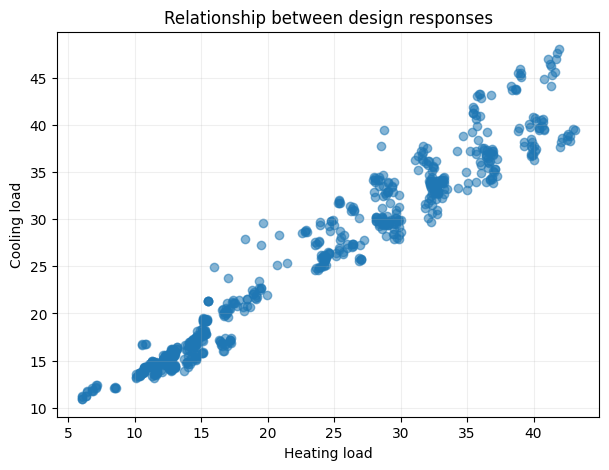

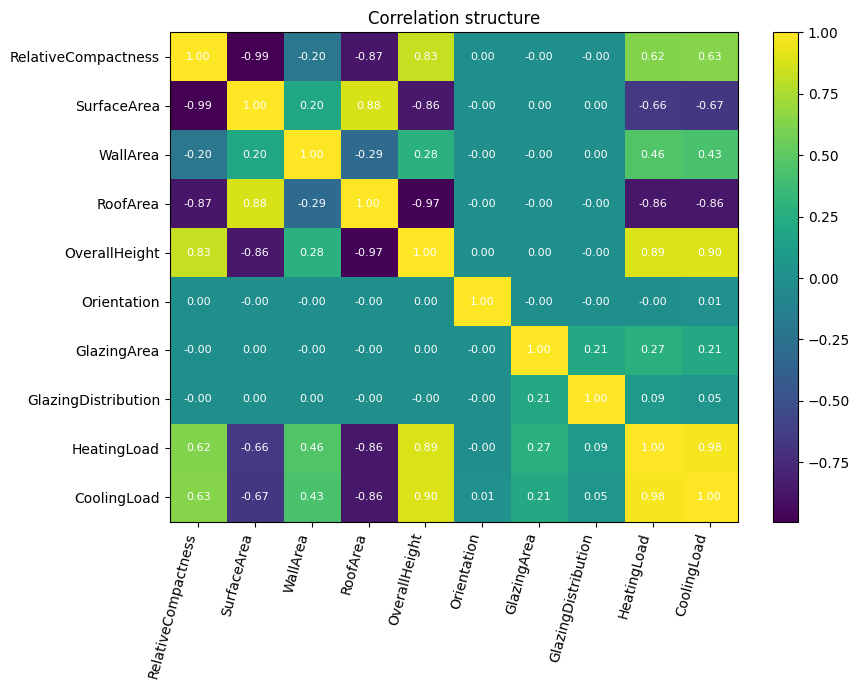

In [ ]:
fig,ax=plt.subplots(figsize=(7,5))
ax.scatter(df["HeatingLoad"],df["CoolingLoad"],alpha=.55)
ax.set(xlabel="Heating load",ylabel="Cooling load",title="Relationship between design responses")
ax.grid(alpha=.2); plt.show()

corr=df.corr(numeric_only=True)
fig,ax=plt.subplots(figsize=(9,7))
im=ax.imshow(corr.values,aspect="auto")
ax.set_xticks(range(len(corr.columns)),corr.columns,rotation=75,ha="right")
ax.set_yticks(range(len(corr.columns)),corr.columns)
fig.colorbar(im,ax=ax); ax.set_title("Correlation structure")

# Add correlation values to the heatmap
for i in range(len(corr.columns)):
    for j in range(len(corr.columns)):
        text = ax.text(j, i, f"{corr.iloc[i, j]:.2f}",
                       ha="center", va="center", color="w", fontsize=8)

plt.tight_layout(); plt.show()

# 7. Prediction problem formulation

Let

$$
\mathbf{x}=[x_1,\ldots,x_8]^T
$$

represent building descriptors and

$$
y_H=f_H(\mathbf{x}),\qquad y_C=f_C(\mathbf{x})
$$

represent heating and cooling loads.

We first learn $\hat f_H$. The same process can be repeated for cooling load or implemented as multi-output regression.

### Train/test separation

A test set simulates future, unseen designs. Model choices should be made without using the test outcomes as training information.

### Data leakage

Leakage occurs when information unavailable at prediction time enters training. Examples include:
- preprocessing the entire dataset before splitting;
- using future measurements to predict the past;
- including a derived variable that directly contains the target;
- repeatedly tuning models against the final test set.


In [ ]:
features=["RelativeCompactness","SurfaceArea","WallArea","RoofArea","OverallHeight",
          "Orientation","GlazingArea","GlazingDistribution"]
X=df[features]; y=df["HeatingLoad"]
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.25,random_state=RANDOM_STATE)
print("Training designs:",len(X_train)," Test designs:",len(X_test))

Training designs: 576  Test designs: 192


# 8. Baselines and model hierarchy

A useful model-development strategy starts simple.

### Linear regression
Tests whether an approximately additive linear mapping is adequate.
$$\hat f_H = \beta_0 + \sum_{i=1}^{8}\beta_i x_i$$
The coefficients $\beta_i$ are estimated by minimizing the squared prediction error.

### Quadratic response surface
Adds curvature and interactions between design variables. This connects directly to classical optimum design and surrogate modeling.
$$
\hat f_H =
\beta_0
+\sum_{i=1}^{8}\beta_i x_i
+\sum_{i=1}^{8}\beta_{ii}x_i^2
+\sum_{i<j}\beta_{ij}x_i x_j.
$$

Thus, the model captures linear effects, quadratic effects, and pairwise interactions.

### Random Forest / ensemble trees
A Random Forest combines predictions from $B$ regression trees:

$$
\hat f_H
=
\frac{1}{B}\sum_{b=1}^{B}T_b(\mathbf{x}),
$$

where $T_b(\mathbf{x})$ is the prediction from the $b$th regression tree. Unlike the linear and quadratic models, the Random Forest does not assume a predefined functional relationship and can capture complex nonlinearities and interactions.

### Gradient Boosting Regressor
Gradient Boosting constructs regression trees sequentially, with each new tree attempting to correct the errors of the current model:

$$
\hat f_H
=
\hat{f_H}_0+
\eta\sum_{m=1}^{M}T_m(\mathbf{x}),
$$

where $T_m(\mathbf{x})$ is the $m$th regression tree, $M$ is the number of boosting stages, and $\eta$ is the learning rate. Unlike Random Forest, the trees are therefore added sequentially rather than independently.

The purpose is not to assume that “AI” must win. The correct question is whether additional complexity produces reliable decision-relevant improvement.


In [ ]:
models={
 "Linear":make_pipeline(StandardScaler(),LinearRegression()),
 "Quadratic":make_pipeline(StandardScaler(),PolynomialFeatures(2,include_bias=False),LinearRegression()),
 "Random Forest":RandomForestRegressor(n_estimators=500,min_samples_leaf=2,random_state=RANDOM_STATE,n_jobs=-1),
 "Gradient Boosting":GradientBoostingRegressor(random_state=RANDOM_STATE)
}
rows=[]
for name,m in models.items():
    m.fit(X_train,y_train); p=m.predict(X_test)
    rows.append([name,mean_absolute_error(y_test,p),mean_squared_error(y_test,p)**.5,r2_score(y_test,p)])
results=pd.DataFrame(rows,columns=["Model","MAE","RMSE","R2"]).sort_values("RMSE")
display(results.round(4))

,Model,MAE,RMSE,R2
3,Gradient Boosting,0.2983,0.4087,0.9983
2,Random Forest,0.3851,0.6097,0.9962
1,Quadratic,0.5397,0.7489,0.9943
0,Linear,2.0340,2.9758,0.9099


# 9. What do the validation metrics mean?

For regression:

$$
MAE=\frac{1}{n}\sum_i |y_i-\hat y_i|
$$

$$
RMSE=\sqrt{\frac{1}{n}\sum_i(y_i-\hat y_i)^2}
$$

$$
R^2=1-\frac{\sum_i(y_i-\hat y_i)^2}{\sum_i(y_i-\bar y)^2}.
$$

- **MAE** is easy to interpret in response units.
- **RMSE** penalizes large errors more strongly.
- **$R^2$** measures explained variation relative to a mean baseline.

No single metric answers whether a model is safe or useful for design. A model can have excellent average error but fail near constraints, rare regimes, or the optimum.


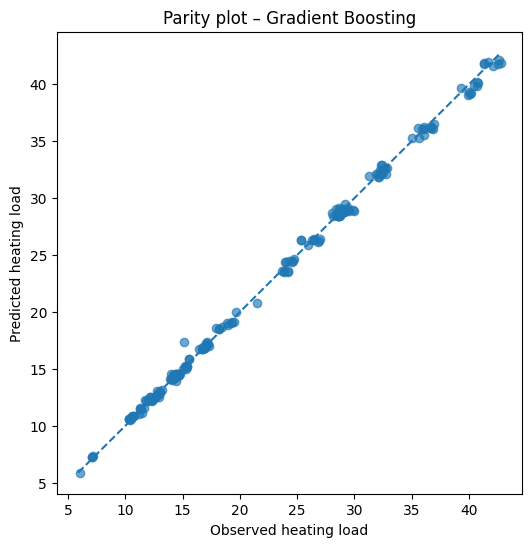

In [ ]:
best_name=results.iloc[0]["Model"]; best=models[best_name]
p=best.predict(X_test)
fig,ax=plt.subplots(figsize=(6,6)); ax.scatter(y_test,p,alpha=.65)
lo=min(y_test.min(),p.min()); hi=max(y_test.max(),p.max()); ax.plot([lo,hi],[lo,hi],"--")
ax.set(xlabel="Observed heating load",ylabel="Predicted heating load",title=f"Parity plot – {best_name}")
plt.show()

# 10. Interpretability: what has the model learned?

Prediction alone tells us **what** the model expects. Engineering design often also asks **why**.

Interpretability can support:
- debugging;
- detecting leakage or spurious relationships;
- identifying influential variables;
- communicating design tradeoffs;
- comparing learned behavior with physical expectations.

### Permutation importance
Permutation importance evaluates how strongly a trained model relies on each input variable. First, the baseline prediction error is calculated using the original validation data. The values of feature $x_j$ are then randomly shuffled while all other features remain unchanged. Its importance can be expressed as

$$
I_j = E_{\mathrm{permuted},j} - E_{\mathrm{baseline}},
$$

where $E_{\mathrm{baseline}}$ is the original prediction error and $E_{\mathrm{permuted},j}$ is the error after permuting feature $j$.

A **large increase in error** indicates that the feature is important to the model's predictions, while an importance near zero indicates limited predictive contribution. Permutation importance measures **model reliance**, not causality or the direction of a feature's effect.



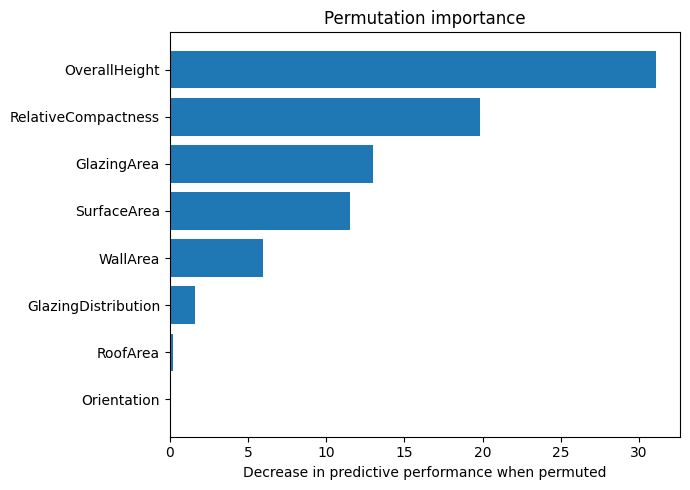

In [ ]:
gbr=models["Gradient Boosting"]
pi=permutation_importance(gbr,X_test,y_test,n_repeats=20,random_state=RANDOM_STATE,scoring="neg_mean_squared_error")
imp=pd.DataFrame({"Feature":features,"Importance":pi.importances_mean}).sort_values("Importance")
fig,ax=plt.subplots(figsize=(7,5)); ax.barh(imp.Feature,imp.Importance); ax.set_title("Permutation importance")
ax.set_xlabel("Decrease in predictive performance when permuted"); plt.tight_layout(); plt.show()

# 11. Partial dependence and design sensitivity

A partial dependence plot estimates the average model response as one design variable changes while averaging over the observed distribution of other variables.

$$
PD_j(z)
=
\frac{1}{N}
\sum_{i=1}^{N}
\hat{f}\left(z,\mathbf{x}_{-j}^{(i)}\right),
$$

where $z$ is a selected value of feature $x_j$ and $\mathbf{x}_{-j}^{(i)}$ represents the remaining features for observation $i$.

It can help answer:
- Is the learned relationship monotonic?
- Is there an apparent threshold?
- Does performance saturate?
- Which variable ranges appear favorable?

But partial dependence may evaluate combinations that are rare or physically coupled in the actual data. It should therefore be interpreted together with domain knowledge and data coverage.

An **upward trend** in the partial dependence plot indicates that increasing the feature tends to increase the predicted response, while a **downward trend** indicates the opposite. Curvature, plateaus, and turning points can reveal nonlinear relationships.

Thus, the two methods provide complementary information:

$
\boxed{\text{Permutation Importance: How important is the variable?}}
$

$
\boxed{\text{Partial Dependence: How does the variable affect the prediction?}}
$


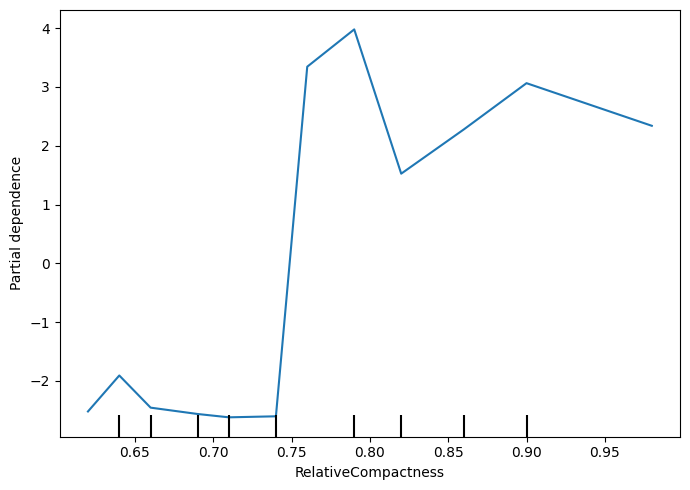

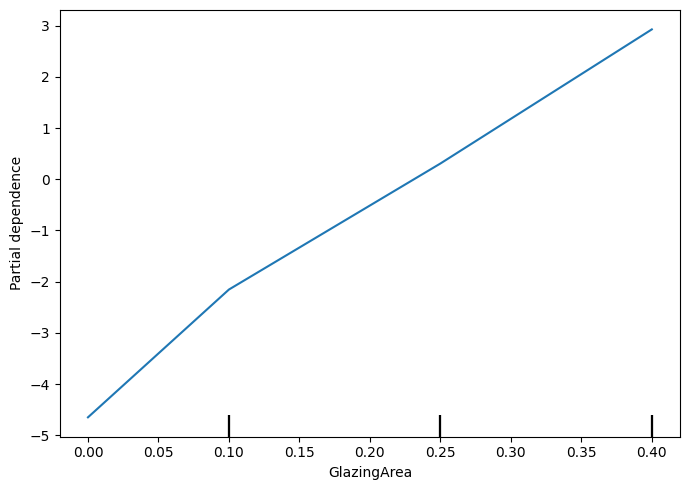

In [ ]:
fig,ax=plt.subplots(figsize=(7,5))
PartialDependenceDisplay.from_estimator(gbr,X_test,["RelativeCompactness"],ax=ax)
plt.tight_layout(); plt.show()
fig,ax=plt.subplots(figsize=(7,5))
PartialDependenceDisplay.from_estimator(gbr,X_test,["GlazingArea"],ax=ax)
plt.tight_layout(); plt.show()

# 12. Prediction is not optimization

A predictor answers

$
\mathbf{x}\rightarrow \hat y.
$

A design problem reverses the direction:

$
\text{desired performance}\rightarrow \text{choose }\mathbf{x}.
$

Once an ML model is connected to a search algorithm, we can solve an approximate problem such as

$
\min_{\mathbf{x}\in\Omega}\hat f_H(\mathbf{x}).
$

However, three cautions immediately appear:

1. **Controllability:** not every predictor should be treated as a design variable.
2. **Feasibility:** arbitrary combinations of independently bounded features may be physically impossible.
3. **Model exploitation:** an optimizer actively searches for regions where model error can be advantageous.

Therefore AI-connected optimization requires stronger verification than ordinary prediction.


# 13. Data-supported candidate design

For observational or structured datasets, a safe first step is often **candidate ranking** rather than unconstrained continuous optimization.

We can ask the ML model to score known feasible configurations and identify promising designs. This keeps recommendations inside the empirical design manifold.


In [ ]:
candidate=df[features].copy()
candidate["PredictedHeating"]=gbr.predict(candidate)
candidate["ObservedHeating"]=df["HeatingLoad"].values
print("Five designs with lowest RF-predicted heating load:")
display(candidate.nsmallest(5,"PredictedHeating").round(3))

Five designs with lowest RF-predicted heating load:


,RelativeCompactness,SurfaceArea,WallArea,RoofArea,OverallHeight,Orientation,GlazingArea,GlazingDistribution,PredictedHeating,ObservedHeating
27,0.74,686.0,245.0,220.5,3.5,5,0.0,0,5.881,6.04
25,0.74,686.0,245.0,220.5,3.5,3,0.0,0,6.066,6.05
26,0.74,686.0,245.0,220.5,3.5,4,0.0,0,6.066,6.01
24,0.74,686.0,245.0,220.5,3.5,2,0.0,0,6.086,6.07
29,0.71,710.5,269.5,220.5,3.5,3,0.0,0,6.388,6.40


# 14. Uncertainty and domain of applicability

A design model should answer not only “What do I predict?” but also “How much evidence supports this prediction?”

Important uncertainty sources include:

### Aleatoric uncertainty
Irreducible variability in measurements or operation.

### Epistemic uncertainty
Uncertainty due to limited knowledge or sparse data. This can often be reduced by acquiring data.

### Distribution shift
Future designs or operating conditions differ from training conditions.

### Extrapolation / out-of-distribution design
The proposed design lies outside the region supported by training data.

For design, these concerns are critical because optimization tends to push toward boundaries and unusual combinations. A high-performing model on an ordinary random test split does not guarantee trustworthy extrapolation.


# 15. A simple familiarity measure

One practical way to flag unsupported designs is distance to the training data after scaling. For candidate $\mathbf{x}$, define

$$
d(\mathbf{x})=\min_i\|\tilde{\mathbf{x}}-\tilde{\mathbf{x}}^{(i)}_{train}\|_2.
$$

Large distance means the candidate is unlike observed training examples. This is not a complete uncertainty model, but it illustrates a useful design principle:

> **Do not treat every AI prediction as equally supported.**


In [ ]:
ph=gbr.predict(df[features])
sc=StandardScaler().fit(X_train)
Xt=sc.transform(X_train)
Xcand=sc.transform(df[features])
d=np.min(np.linalg.norm(Xcand[:,None,:]-Xt[None,:,:],axis=2),axis=1)
check=pd.DataFrame({"PredictedHeating":ph,"FamiliarityDistance":d})
display(check.sort_values("PredictedHeating").head(10).round(3))

,PredictedHeating,FamiliarityDistance
27,5.881,0.684
25,6.066,0.000
26,6.066,0.000
24,6.086,0.000
29,6.388,0.000
30,6.388,0.000
31,6.403,0.000
28,6.436,0.000
33,6.787,0.000
34,6.787,0.000


# 16. Physics-informed and hybrid AI design

Purely data-driven models are not the only option. Engineering knowledge can be connected to AI in several ways:

### Physics-derived features
Use nondimensional groups, conservation-based quantities, residuals, or physically meaningful transformations as ML inputs.

### Physics-based constraints
Reject predictions/designs that violate mass, energy, geometry, stability, or material constraints.

### Residual learning
Use ML to learn the discrepancy between a physics model and observations:

$$
y=f_{physics}(\mathbf{x})+\Delta_{ML}(\mathbf{x}).
$$

### Physics-informed loss functions
Penalize violations of known equations during model training.

### Multifidelity learning
Combine inexpensive low-fidelity simulation with sparse high-fidelity experiments.

Hybrid approaches are often attractive because they use data where physics is incomplete while retaining known engineering structure.


# 17. Generative AI and engineering design

“AI-connected design” now also includes generative systems. Their roles can include:

- generating concept alternatives;
- converting natural-language requirements into structured design variables;
- assisting CAD scripting and parametric model creation;
- retrieving analogous designs;
- proposing optimization constraints or test cases;
- summarizing simulation/experiment results;
- acting as an interface to engineering tools.

However, generative AI outputs are **proposals**, not verified engineering facts. Geometry, equations, code, constraints, materials, standards, and performance claims require verification.

A useful architecture is therefore

$
\boxed{\text{Human requirements}\rightarrow\text{AI proposal}\rightarrow\text{engineering tools}\rightarrow\text{verification}\rightarrow\text{human decision}}
$


# 18. Human-in-the-loop AI-connected design

There are several levels of automation:

### AI as analyst
Summarizes data and identifies patterns.

### AI as predictor
Estimates performance for candidate designs.

### AI as recommender
Ranks or proposes candidate designs.

### AI as optimizer
Searches the design space using learned models.

### AI as adaptive design agent
Chooses new simulations/experiments, updates models, and proposes subsequent designs.

As autonomy increases, requirements for validation, uncertainty estimation, traceability, constraint enforcement, and human oversight also increase.


# 19. Closed-loop AI-connected design

A mature AI-connected workflow is iterative:

$
\boxed{
\text{Requirements}
\rightarrow\text{Data/physics}
\rightarrow\text{AI model}
\rightarrow\text{Design search}
\rightarrow\text{Verification}
\rightarrow\text{New evidence}
\rightarrow\text{Model update}}
$

This connects directly with topics already encountered in optimum design:
- DOE determines where information is collected;
- surrogate modeling approximates expensive mappings;
- optimization identifies promising designs;
- uncertainty determines confidence;
- sequential design determines what should be evaluated next;
- AI expands the types of mappings and information that can be learned.


# 20. Common failure modes

1. **Optimizing the model rather than the engineering system.**
2. **Data leakage** that makes validation unrealistically optimistic.
3. **Extrapolation** beyond the data-supported domain.
4. **Spurious correlation** mistaken for causal design leverage.
5. **Ignoring feasibility** when treating observed variables as independently controllable.
6. **Ignoring uncertainty** and presenting point predictions as certainty.
7. **Metric fixation:** selecting a model only because its RMSE is lowest.
8. **No baseline:** using a complex AI model without showing that it improves on simpler alternatives.
9. **No verification:** deploying a recommended optimum without simulation/experiment confirmation.
10. **Automation bias:** accepting an AI recommendation because it appears quantitative or sophisticated.


# 21. A decision-oriented evaluation framework

For AI-connected design, evaluate at least four layers:

### Layer 1 – Predictive performance
MAE, RMSE, $R^2$, calibration, classification metrics when appropriate.

### Layer 2 – Engineering validity
Physical plausibility, constraint satisfaction, dimensional consistency, expected trends.

### Layer 3 – Design utility
Does the model identify better designs? Does it preserve rankings? Is the predicted optimum verified?

### Layer 4 – Trustworthiness
Robustness, familiarity/OOD, uncertainty, explanation stability, reproducibility, bias, traceability.

This is a stronger standard than evaluating AI only as a prediction algorithm.
